In [1]:
import numpy as np
from rich import print
from contingency import Contingent
import contingency.plots as cntyplt
import matplotlib.pyplot as plt

# from contingency.plots import PR_contour,ROC_contour


rng=np.random.default_rng(2)
np.set_printoptions(formatter={'float_kind':"{:.5g}".format})
n_obs=1000
# y_true = np.array([0,1,0,0,1,1,0,0]).astype(bool)
y_true = (y_src:=rng.random(n_obs)>0.5).astype(bool)
# y_prob = np.array([0.1,0.8,0.1,.7,.25,0.68,0.5,0.6])
y_pred = np.where(rng.random(n_obs)<0.05, 1-y_true, y_true).astype(bool)

# y_pred = np.array([0,1,0,1,0,1,0,1]).astype(bool)
y_prob = 10*rng.beta(
    np.where(y_true, 4, 2.),
    np.where(y_true, 2., 4)
)

In [2]:
# M = Contingent(y_pred = y_pred, y_true=y_true)
M = Contingent.from_scalar(y_true, y_prob)

f1_thres,f1_opt = M.optimize('F', include_thres=True)
mcc_thres,mcc_opt = M.optimize('mcc', include_thres=True)
M.imbalance

np.float64(1.012072434607646)

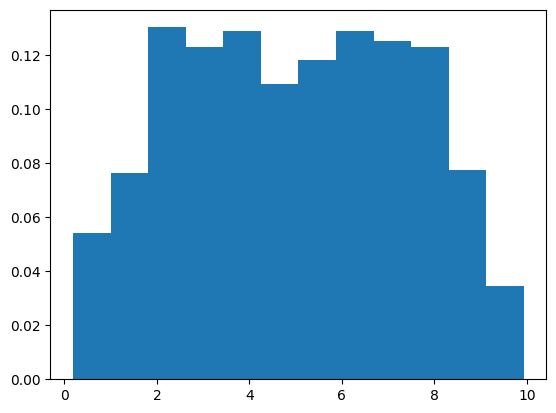

In [3]:
plt.hist(y_prob, bins='auto', density=True);

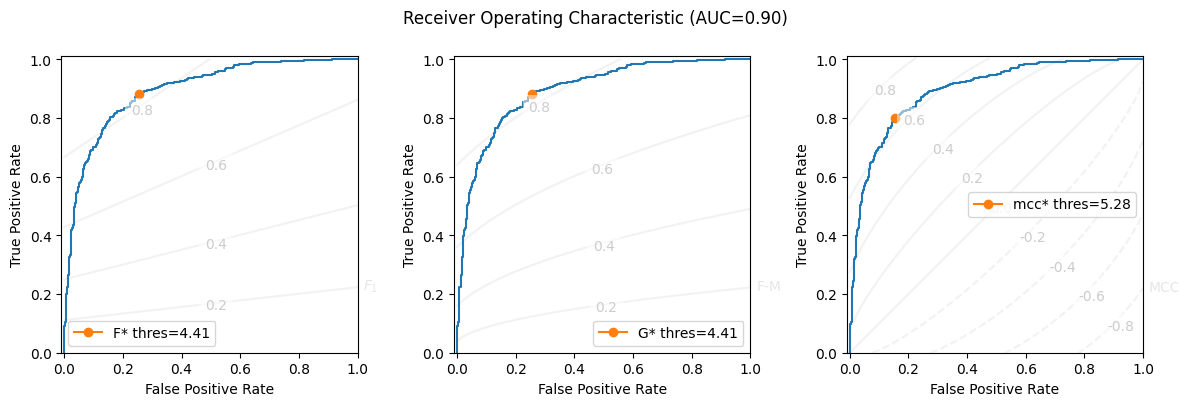

In [4]:
f,axes = plt.subplots(ncols=3, figsize=(12,4))
f.suptitle('Receiver Operating Characteristic ' + f'(AUC={M.expected('auc'):.2f})')

for metric, ax in zip(['F', 'G', 'mcc'], axes.flatten()):
    met_thres,met_opt = M.optimize(metric, include_thres=True)
    
    cntyplt.ROC_contour(M.imbalance, metric, ax=ax)
    ax.plot(1-M.TNR, M.TPR)
    ax.plot(met_opt.FPR, met_opt.TPR, marker='o', label=metric+f'* thres={met_thres:.2f}')
    # ax.plot(mcc_opt.FPR, mcc_opt.TPR, marker='o', label=f'MCC thres={mcc_thres:.2f}', c='g')
    
    ax.legend()
plt.tight_layout()

# plt.gca().spines[['top', 'right']].set_visible(False)

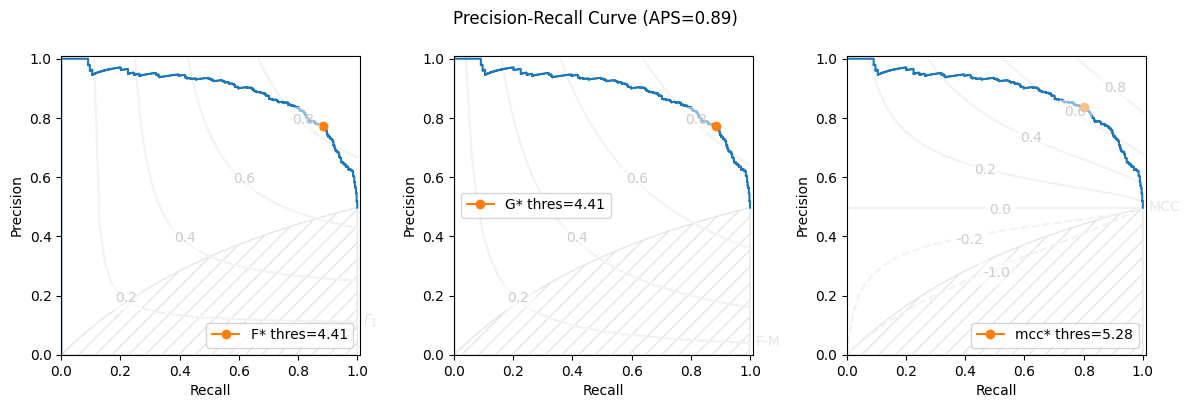

In [5]:
f,axes = plt.subplots(ncols=3, figsize=(12,4))
f.suptitle('Precision-Recall Curve ' + f'(APS={M.expected('aps'):.2f})')

for metric, ax in zip(['F', 'G', 'mcc'], axes.flatten()):
    met_thres,met_opt = M.optimize(metric, include_thres=True)
    
    cntyplt.PR_contour(M.imbalance, metric, show_lower_bound=True, ax=ax)
    ax.step(M.recall, M.precision, where='post')
    ax.plot(met_opt.recall, met_opt.precision, marker='o', label=metric+f'* thres={met_thres:.2f}')
    # ax.plot(mcc_opt.FPR, mcc_opt.TPR, marker='o', label=f'MCC thres={mcc_thres:.2f}', c='g')
    
    ax.legend()
plt.tight_layout()

np.float64(1.012072434607646)

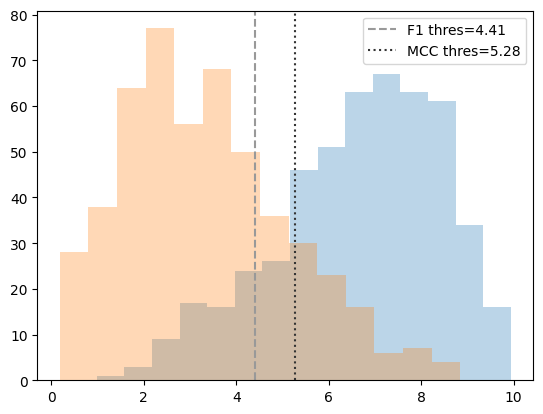

In [6]:
# def true_pred_dists(y_true, y_pred, **hist_kws): 

plt.hist(y_prob[y_true], bins='auto', alpha=0.3, color='C0')
plt.hist(y_prob[~y_true], bins='auto', alpha=0.3, color='C1')
# plt.axvline(0.5, color='0.4', ls='--')
plt.axvline(f1_thres, ls='--', c='0.6', label=f'F1 thres={f1_thres:.2f}')
plt.axvline(mcc_thres, ls=':', c='0.2', label=f'MCC thres={mcc_thres:.2f}')
plt.legend()
M.imbalance

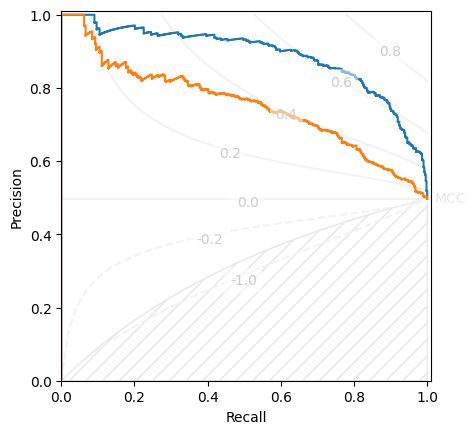

In [7]:
y_new = y_src +rng.normal(size=n_obs)
M_new = Contingent.from_scalar(y_true, y_new)

cntyplt.PR_contour(M.imbalance, 'mcc', show_lower_bound=True)
plt.step(M.recall, M.precision, where='post')
plt.step(M_new.recall, M_new.precision, where='post')


# ax=plt.gca()

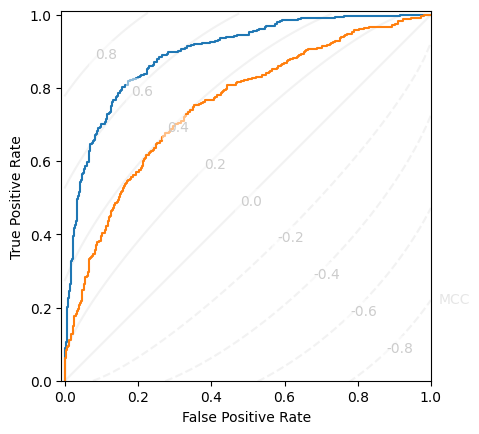

In [8]:
cntyplt.ROC_contour(M.imbalance, 'mcc')
plt.plot(M.FPR, M.TPR)
plt.plot(M_new.FPR, M_new.TPR)

array([0, 1, 1, ..., 1, 1, 1], shape=(1001,))

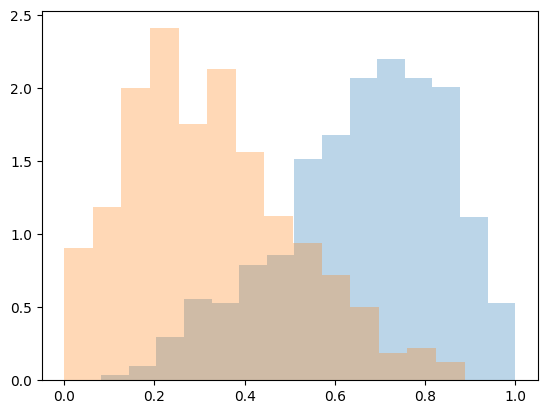

In [9]:
# np.diff(M.y_pred.sum(axis=1))
# plt.plot(M.weights)

ysort = M.y_true[0,np.argmax(np.diff(M.y_pred, axis=0),axis=1)]
plt.hist(M.weights[:-1][ysort], bins='auto',alpha=0.3,density=True)
plt.hist(M.weights[:-1][~ysort], bins='auto', alpha=0.3,density=True)
np.diff(M.y_pred, axis=0).sum(axis=1)

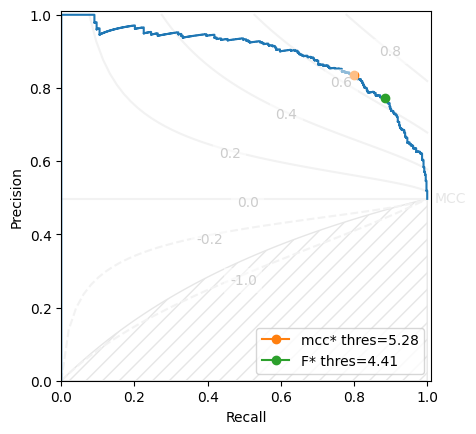

In [26]:
M.plot.precision_recall(
    optimize=['mcc', 'F'], 
    isolines='mcc', 
    show_lower_bound=True
)
plt.legend()

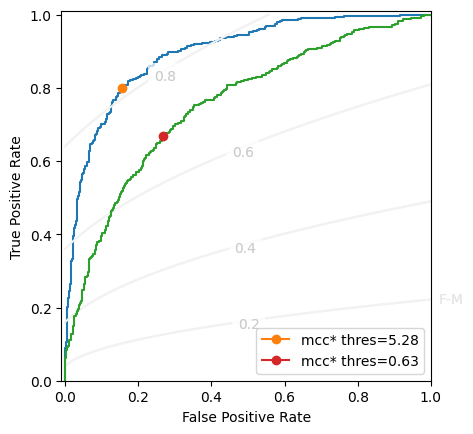

In [35]:
M.plot.receiver_operating_characteristic(
    optimize='mcc',
    isolines='G'
)

M_new.plot.receiver_operating_characteristic(
    optimize='mcc',
    isolines='G',
    ax=plt.gca()
)
plt.legend()

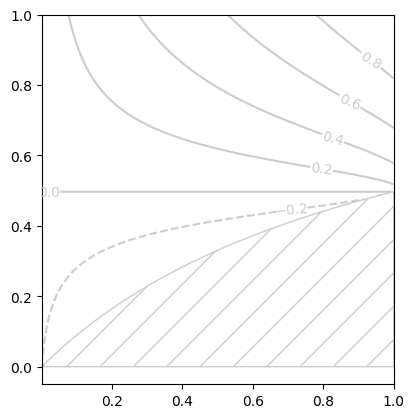

In [12]:


## Could migrate to a contour-based system....\shrug
r = M.imbalance
# x = np.linspace(1e-4, 1, 300)
grid = np.linspace(1e-4, 1, 500)
R,P = np.meshgrid(grid,grid)
valid = P >= R / (R + r)
MCC = np.where(
    valid,
    np.sqrt(R) * (P * (r + 1) - 1) / np.sqrt(np.maximum(r * (P * (r + 1) - R), 1e-12)),
    np.nan,
)
# MCC = np.sqrt(X)*(Y*(1.63+1)-1)/np.sqrt(1.63*(Y*(1.63+1)-X))
C = plt.contour(R,P,MCC, levels=[-0.2, 0., 0.2, 0.4, 0.6, 0.8], colors='0.8')
plt.clabel(C)
plt.fill_between(grid, grid/(grid+r), edgecolor='0.8', facecolor='none',hatch='/' )
plt.gca().set_aspect(1)

/tmp/ipykernel_3051168/1892499211.py:3: RuntimeWarning: divide by zero encountered in divide
  plt.plot(rg:=(M.recall-pi)/((1-pi)*M.recall),pg:=(M.precision-pi)/((1-pi)*M.precision))
/tmp/ipykernel_3051168/1892499211.py:11: RuntimeWarning: invalid value encountered in subtract
  u = np.clip(0.5 * (rg - pg + 1.0),0,1)


np.float64(0.6483537428192563)

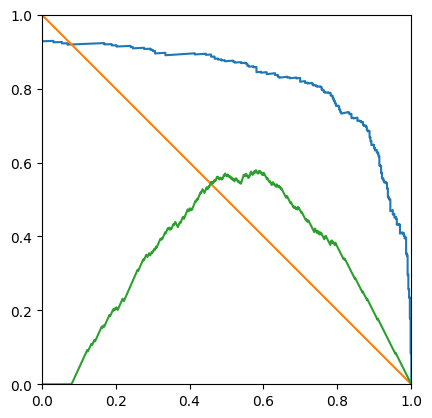

In [80]:
pi = 1/(1+r)
# plt.plot(rg:=1-np.log(M.recall)/np.log(pi), pg:=1-np.log(M.precision)/np.log(pi))  # 
plt.plot(rg:=(M.recall-pi)/((1-pi)*M.recall),pg:=(M.precision-pi)/((1-pi)*M.precision))
plt.plot(np.linspace(0,1), np.linspace(1,0))
plt.gca().set(aspect=1,ylim=(0,1),xlim=(0,1))

 # pg = np.clip(pg, 0.0, 1.0)
 #    rg = np.clip(rg, 0.0, 1.0)

# Height above the all-positive F1 diagonal (PG + RG = 1)
u = np.clip(0.5 * (rg - pg + 1.0),0,1)
v = np.clip(np.maximum(0.0, pg + rg - 1.0),0,1)  # already scaled by 2x so peak (1, 1) -> v = 1.0!
u[np.isnan(u)]=0.
# Sort by u along the diagonal and integrate
order_u = np.argsort(u)

plt.plot(u[order_u], v[order_u])
2*np.trapezoid(v[order_u], x=u[order_u])# excess

# rg_anc = np.concatenate([[0.0], rg, [1.0]])
# pg_anc = np.concatenate([[1.0], pg, [0.0]])

# # Method 1: Vertical excess above PG + RG = 1
# excess = np.maximum(0.0, pg_anc - (1.0 - rg_anc))
# m1 = float(2.0 * np.trapezoid(excess, x=rg_anc))

# # Method 2: Rotated along the diagonal (keep threshold order, NO argsort on u!)
# u = 0.5 * (rg_anc - pg_anc + 1.0)
# v = np.maximum(0.0, pg_anc + rg_anc - 1.0)
# m2 = float(2.0 * np.trapezoid(v, x=u))

# m1,m2

np.float64(0.49678521627170064)

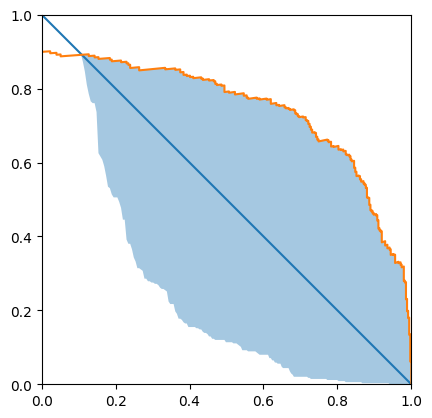

In [81]:
pi = 1/(1+M.imbalance)

# Sort by increasing recall (descending threshold)
order = np.argsort(M.recall)
P, R = M.precision[::-1], M.recall[::-1]
# P, R = M.precision, M.recall

# Interpolate exact Precision where Recall crosses pi (so RG = 0 cleanly)
# and discard all points with R <= pi (avoids R=0 -> -inf completely)
above_pi = R > pi
# if not np.any(above_pi):
#     return 0.0

p_at_pi = float(np.interp(pi, R, P))
P_valid = np.concatenate([[p_at_pi], P[above_pi]])
R_valid = np.concatenate([[pi], R[above_pi]])


#### F1-gain
# rg = (R_valid - pi) / ((1.0 - pi) * R_valid)
# with np.errstate(divide="ignore", invalid="ignore"):
#     pg = (P_valid - pi) / ((1.0 - pi) * P_valid)

#### FM-gain
rg =1-np.log(R_valid)/np.log(pi)
with np.errstate(divide="ignore", invalid="ignore"):
    pg = 1-np.log(P_valid)/np.log(pi)

####

# pg = np.clip(pg, 0.0, 1.0)
# rg = np.clip(rg, 0.0, 1.0)

# Anchor the endpoints of the diagonal: (0, 1) and (1, 0)
rg_anc = np.concatenate([[0.0], rg, [1.0]])
pg_anc = np.concatenate([[1.0], pg, [0.0]])

# Excess height above PG + RG = 1, doubled to normalize [0, 0.5] ->
# excess = np.maximum(0.0, pg_anc + rg_anc - 1.0)

# Rotated coordinates: base u in, peak height v = 1 at (RG=1, PG=1)
u = 0.5 * (rg_anc - pg_anc + 1.0)
v = np.maximum(0.0, pg_anc + rg_anc - 1.0)

# Triangle area with base=1, max height=1 is 0.5 -> multiply by 2 to normalize to

plt.plot(np.linspace(0,1), np.linspace(1,0))
plt.gca().set(aspect=1,ylim=(0,1),xlim=(0,1))

plt.plot(rg, pg)
plt.fill_between(rg_anc, np.minimum(np.interp(rg_anc, 1-pg_anc, 1-rg_anc), 1-rg_anc), np.maximum(pg_anc, 1-rg_anc), alpha=0.4)
# plt.plot(u,2*v)
# plt.fill_between(1-rg_anc, 1-pg_anc, rg_anc, alpha=0.4)
# 2.0 * np.trapezoid(excess, x=rg_anc)
np.trapezoid(2.0*v, x=u)

np.float64(0.4077653279720873)

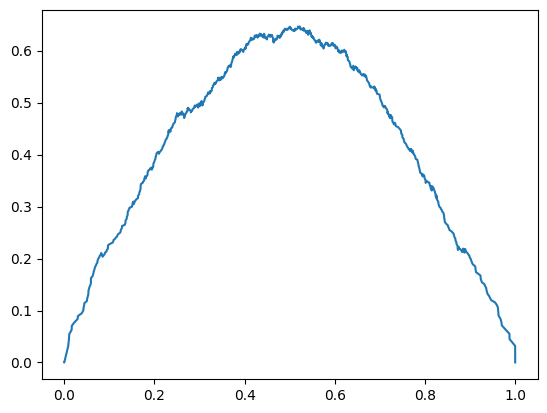

In [84]:
plt.plot(M.weights, M.mcc)
M.expected('mcc')

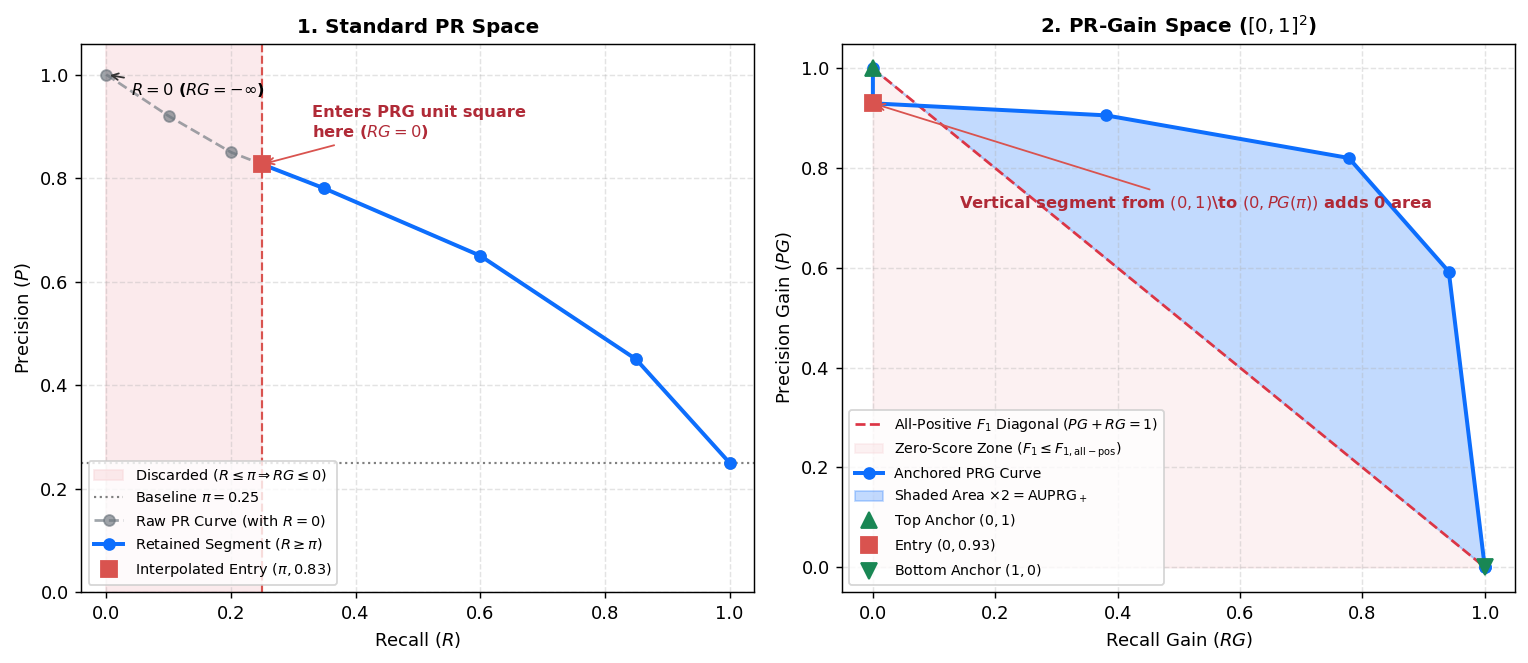

In [105]:
import numpy as np
import matplotlib.pyplot as plt

pi = 0.25
R = np.array([0.0, 0.10, 0.20, 0.35, 0.60, 0.85, 1.0])
P = np.array([1.0, 0.92, 0.85, 0.78, 0.65, 0.45, 0.25])

# Interpolate where Recall crosses pi
p_at_pi = float(np.interp(pi, R, P))
R_valid = np.concatenate([[pi], R[R > pi]])
P_valid = np.concatenate([[p_at_pi], P[R > pi]])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2), dpi=130)

# --- Left Panel: Standard PR Space ---
ax1.axvspan(0, pi, color="#f8d7da", alpha=0.5, label=r"Discarded ($R \leq \pi \Rightarrow RG \leq 0$)")
ax1.axhline(pi, color="gray", linestyle=":", linewidth=1.2, label=rf"Baseline $\pi = {pi}$")
ax1.axvline(pi, color="#d9534f", linestyle="--", linewidth=1.2)

ax1.plot(R, P, "o--", color="#6c757d", alpha=0.65, label="Raw PR Curve (with $R=0$)")
ax1.plot(R_valid, P_valid, "o-", color="#0d6efd", linewidth=2.2, label=r"Retained Segment ($R \geq \pi$)")
ax1.plot(pi, p_at_pi, "s", color="#d9534f", markersize=9, zorder=5, label=rf"Interpolated Entry $(\pi, {p_at_pi:.2f})$")

ax1.annotate(r"$R=0$ ($RG = -\infty$)", xy=(0, 1.0), xytext=(0.04, 0.96),
             arrowprops=dict(arrowstyle="->", color="#333"), fontsize=9, fontweight="bold")
ax1.annotate("Enters PRG unit square\nhere ($RG=0$)", xy=(pi, p_at_pi), xytext=(0.33, 0.88),
             arrowprops=dict(arrowstyle="->", color="#d9534f"), fontsize=9, color="#b02a37", fontweight="bold")

ax1.set_title("1. Standard PR Space", fontsize=11, fontweight="bold")
ax1.set_xlabel("Recall ($R$)")
ax1.set_ylabel("Precision ($P$)")
ax1.set_xlim(-0.04, 1.04)
ax1.set_ylim(0.0, 1.06)
ax1.grid(True, linestyle="--", alpha=0.35)
ax1.legend(loc="lower left", fontsize=8)

# --- Right Panel: PRG Space ---
rg = (R_valid - pi) / ((1.0 - pi) * R_valid)
pg = (P_valid - pi) / ((1.0 - pi) * P_valid)

diag_x = np.linspace(0, 1, 100)
ax2.plot(diag_x, 1 - diag_x, "--", color="#dc3545", linewidth=1.5, label=r"All-Positive $F_1$ Diagonal ($PG + RG = 1$)")
ax2.fill_between(diag_x, 0, 1 - diag_x, color="#f8d7da", alpha=0.35, label=r"Zero-Score Zone ($F_1 \leq F_{1,\mathrm{all-pos}}$)")

rg_anc = np.concatenate([[0.0], rg, [1.0]])
pg_anc = np.concatenate([[1.0], pg, [0.0]])
ax2.plot(rg_anc, pg_anc, "o-", color="#0d6efd", linewidth=2.2, label="Anchored PRG Curve")

rg_fine = np.linspace(0, 1, 300)
pg_fine = np.interp(rg_fine, rg_anc, pg_anc)
excess = np.maximum(0.0, pg_fine - (1.0 - rg_fine))
ax2.fill_between(rg_fine, 1.0 - rg_fine, 1.0 - rg_fine + excess, color="#0d6efd", alpha=0.25, label=r"Shaded Area $\times 2 = \mathrm{AUPRG}_+$")

ax2.plot(0, 1, "^", color="#198754", markersize=9, zorder=6, label="Top Anchor $(0, 1)$")
ax2.plot(rg[0], pg[0], "s", color="#d9534f", markersize=9, zorder=6, label=rf"Entry $(0, {pg[0]:.2f})$")
ax2.plot(1, 0, "v", color="#198754", markersize=9, zorder=6, label="Bottom Anchor $(1, 0)$")

ax2.annotate(r"Vertical segment from $(0,1)$\to $(0, PG(\pi))$ adds 0 area", xy=(0, pg[0]), xytext=(0.14, 0.72),
             arrowprops=dict(arrowstyle="->", color="#d9534f"), fontsize=9, color="#b02a37", fontweight="bold")

ax2.set_title("2. PR-Gain Space ($[0, 1]^2$)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Recall Gain ($RG$)")
ax2.set_ylabel("Precision Gain ($PG$)")
ax2.set_xlim(-0.05, 1.05)
ax2.set_ylim(-0.05, 1.05)
ax2.grid(True, linestyle="--", alpha=0.35)
ax2.legend(loc="lower left", fontsize=7.8)

plt.tight_layout()
plt.show()


### 
Algebraic Parallels: Odds Space ($F_1$-Gain) vs. Log-Probability Space ($\text{FM}$-Gain)

Let:
* $P = \text{Precision} = \frac{\text{TP}}{\text{TP} + \text{FP}}$
* $R = \text{Recall} = \frac{\text{TP}}{\text{TP} + \text{FN}}$
* $\pi = \text{Positive Prevalence} = \frac{1}{1 + \theta}$ (where $\theta = \frac{N}{P}$)

---

#### 1. $F_1$-Gain $\iff$ Relative Error Odds (Rational / Möbius Geometry)
Define the **False Discovery Odds** and **Miss Odds**:
$$\text{Odds}_{\text{FD}}(P) = \frac{1 - P}{P} = \frac{\text{FP}}{\text{TP}}, \qquad \text{Odds}_{\text{Miss}}(R) = \frac{1 - R}{R} = \frac{\text{FN}}{\text{TP}}$$

And the **Baseline ("All-Positive") Error Odds**:
$$\text{Odds}_{\text{FD}}(\pi) = \frac{1 - \pi}{\pi} = \theta, \qquad \text{Odds}_{\text{Miss}}(\pi) = \frac{1 - \pi}{\pi} = \theta$$

Then Flach & Kull's **Precision-Gain** and **Recall-Gain** are exact relative reductions in odds:
$$\text{PG}_{F_1} = \frac{P - \pi}{(1 - \pi)P} = 1 - \frac{\text{Odds}_{\text{FD}}(P)}{\text{Odds}_{\text{FD}}(\pi)}$$

$$\text{RG}_{F_1} = \frac{R - \pi}{(1 - \pi)R} = 1 - \frac{\text{Odds}_{\text{Miss}}(R)}{\text{Odds}_{\text{Miss}}(\pi)}$$

* **Isometric Metric ($F_1$):** Harmonic mean of $(P, R)$, which is linear in $\text{PG}_{F_1} + \text{RG}_{F_1}$:
  $$F_1 = \frac{2}{\frac{1}{P} + \frac{1}{R}} = \frac{2}{2 + \text{Odds}_{\text{FD}}(P) + \text{Odds}_{\text{Miss}}(R)}$$
* **Geometric Invariant:** Preserves **straight lines** under linear mixtures of confusion matrix counts.

---

#### 2. $\text{FM}$-Gain $\iff$ Normalized Log-Lift (Information / Log-Probability Geometry)
Define the **Log-Lift** (Pointwise Mutual Information) over baseline prevalence $\pi$:
$$\text{Lift}(P) = \ln\left(\frac{P}{\pi}\right), \qquad \text{Lift}(R) = \ln\left(\frac{R}{\pi}\right)$$

Normalizing by the maximum possible lift $\ln(1/\pi) = -\ln(\pi)$ yields **Log-Precision Gain** and **Log-Recall Gain**:
$$\text{PG}_{\text{FM}} = \frac{\ln(P) - \ln(\pi)}{\ln(1) - \ln(\pi)} = 1 - \frac{\ln(P)}{\ln(\pi)}$$

$$\text{RG}_{\text{FM}} = \frac{\ln(R) - \ln(\pi)}{\ln(1) - \ln(\pi)} = 1 - \frac{\ln(R)}{\ln(\pi)}$$

* **Isometric Metric ($\text{FM}$):** Geometric mean of $(P, R)$ (and $\lim_{\text{TN}\to\infty} \text{MCC}$), which is linear in $\text{PG}_{\text{FM}} + \text{RG}_{\text{FM}}$:
  $$\ln(\text{FM}) = \frac{1}{2}\ln(P) + \frac{1}{2}\ln(R)$$
* **Geometric Invariant:** Preserves **multiplicative symmetry** and straight iso-$\text{FM}$ lines in log-probability space.


[AUPRG paper](https://proceedings.neurips.cc/paper/2015/file/33e8075e9970de0cfea955afd4644bb2-Paper.pdf)

### Algebraic Parallels: Error Odds ($F_1$-Gain) vs. Error Log-Survival ($\text{FM}$-Gain)

Let:
* $p_{\text{FD}} = 1 - P = p(Y=0 \mid \hat{Y}=1)$  *(False Discovery Probability)*
* $p_{\text{Miss}} = 1 - R = p(\hat{Y}=0 \mid Y=1)$  *(Miss Probability)*
* $p_0 = 1 - \pi = \frac{\theta}{1 + \theta}$  *(Baseline Error Probability)*

---

#### 1. $F_1$-Gain $\iff$ Relative Error Odds (Rational / Möbius Geometry)
Define the **False Discovery Odds** and **Miss Odds**:
$$\text{Odds}_{\text{FD}} = \frac{p_{\text{FD}}}{1 - p_{\text{FD}}} = \frac{\text{FP}}{\text{TP}}, \qquad \text{Odds}_{\text{Miss}} = \frac{p_{\text{Miss}}}{1 - p_{\text{Miss}}} = \frac{\text{FN}}{\text{TP}}$$

And the **Baseline Error Odds**:
$$\text{Odds}_0 = \frac{p_0}{1 - p_0} = \theta$$

Then Flach & Kull's **Precision-Gain** and **Recall-Gain** are exact relative reductions in error odds:
$$\text{PG}_{F_1} = 1 - \frac{\text{Odds}_{\text{FD}}}{\text{Odds}_0} = 1 - \frac{p_{\text{FD}} / (1 - p_{\text{FD}})}{p_0 / (1 - p_0)}$$

$$\text{RG}_{F_1} = 1 - \frac{\text{Odds}_{\text{Miss}}}{\text{Odds}_0} = 1 - \frac{p_{\text{Miss}} / (1 - p_{\text{Miss}})}{p_0 / (1 - p_0)}$$

* **Isometric Metric ($F_1$):**
  $$F_1 = \frac{2}{2 + \text{Odds}_{\text{FD}} + \text{Odds}_{\text{Miss}}}$$
* **Geometric Invariant:** Preserves **straight lines** under linear mixtures of confusion matrix counts.

---

#### 2. $\text{FM}$-Gain $\iff$ Relative Log-Survival (Information Geometry)
Define the **Log-Survival** (surprisal of *not* making an error, $S(p) = -\ln(1 - p)$):
$$S_{\text{FD}} = -\ln(1 - p_{\text{FD}}), \qquad S_{\text{Miss}} = -\ln(1 - p_{\text{Miss}})$$

And the **Baseline Log-Survival**:
$$S_0 = -\ln(1 - p_0)$$

Then **Log-Precision Gain** and **Log-Recall Gain** are exact relative reductions in error log-survival:
$$\text{PG}_{\text{FM}} = 1 - \frac{S_{\text{FD}}}{S_0} = 1 - \frac{\ln(1 - p_{\text{FD}})}{\ln(1 - p_0)}$$

$$\text{RG}_{\text{FM}} = 1 - \frac{S_{\text{Miss}}}{S_0} = 1 - \frac{\ln(1 - p_{\text{Miss}})}{\ln(1 - p_0)}$$

* **Isometric Metric ($\text{FM}$):**
  $$\text{FM} = \sqrt{(1 - p_{\text{FD}})(1 - p_{\text{Miss}})} = \exp\left(-\frac{S_{\text{FD}} + S_{\text{Miss}}}{2}\right)$$
* **Geometric Invariant:** Preserves **multiplicative survival symmetry** and matches $\lim_{\text{TN}\to\infty} \text{MCC}$.


### Evaluation Geometries: Proportional Odds ($F_1$-Gain) vs. Proportional Hazards ($\text{FM}$-Gain)

Let:
* $p_{\text{FD}} = 1 - P = p(Y=0 \mid \hat{Y}=1)$  *(False Discovery Probability)*
* $p_{\text{Miss}} = 1 - R = p(\hat{Y}=0 \mid Y=1)$  *(Miss Probability)*
* $p_0 = 1 - \pi = \frac{\theta}{1 + \theta}$  *(Baseline Error Probability)*

---

#### 1. $F_1$-Gain $\iff$ Proportional Odds (Logistic Regression Geometry)
Measures the **relative reduction in error odds** ($\text{Odds}(p) = \frac{p}{1 - p}$, i.e., $1 - \text{Odds Ratio}$):

$$\text{Odds}_{\text{FD}} = \frac{p_{\text{FD}}}{1 - p_{\text{FD}}} = \frac{\text{FP}}{\text{TP}}, \qquad \text{Odds}_{\text{Miss}} = \frac{p_{\text{Miss}}}{1 - p_{\text{Miss}}} = \frac{\text{FN}}{\text{TP}}, \qquad \text{Odds}_0 = \frac{p_0}{1 - p_0} = \theta$$

$$\text{PG}_{F_1} = 1 - \frac{\text{Odds}_{\text{FD}}}{\text{Odds}_0} = 1 - \text{OR}_{\text{FD}}$$

$$\text{RG}_{F_1} = 1 - \frac{\text{Odds}_{\text{Miss}}}{\text{Odds}_0} = 1 - \text{OR}_{\text{Miss}}$$

* **Isometric Metric ($F_1$):**
  $$F_1 = \frac{2}{2 + \text{Odds}_{\text{FD}} + \text{Odds}_{\text{Miss}}}$$
* **Key Property:** Preserves **straight lines** under linear mixtures of confusion matrix counts.

---

#### 2. $\text{FM}$-Gain $\iff$ Proportional Hazards (Cox Survival Geometry)
Measures the **relative reduction in cumulative error hazard** ($H(p) = -\ln(1 - p)$, i.e., $1 - \text{Hazard Ratio}$):

$$H_{\text{FD}} = -\ln(1 - p_{\text{FD}}), \qquad H_{\text{Miss}} = -\ln(1 - p_{\text{Miss}}), \qquad H_0 = -\ln(1 - p_0)$$

$$\text{PG}_{\text{FM}} = 1 - \frac{H_{\text{FD}}}{H_0} = 1 - \text{HR}_{\text{FD}}$$

$$\text{RG}_{\text{FM}} = 1 - \frac{H_{\text{Miss}}}{H_0} = 1 - \text{HR}_{\text{Miss}}$$

* **Isometric Metric ($\text{FM}$):**
  $$\text{FM} = \sqrt{(1 - p_{\text{FD}})(1 - p_{\text{Miss}})} = \exp\left(-\frac{H_{\text{FD}} + H_{\text{Miss}}}{2}\right)$$
* **Key Property:** Preserves **multiplicative survival symmetry** and matches $\lim_{\text{TN}\to\infty} \text{MCC}$.


In [ ]:
import sympy as sp

R, P, FPR, t, r, beta = sp.symbols('R P FPR t r beta', positive=True)

# 1. Normalized confusion matrix (P_pos = 1, N_neg = r)
TP = R
FN = 1 - R
FP = r * FPR
TN = r * (1 - FPR)

prec_expr = TP / (TP + FP)  # R / (R + r * FPR)
fpr_from_p = sp.solve(sp.Eq(P, prec_expr), FPR)  # R * (1 - P) / (r * P)

# 2. Define metrics in terms of (R, FPR, r, beta)
metrics = {
    "MCC": (TP * TN - FP * FN) / sp.sqrt((TP + FP) * (TP + FN) * (TN + FP) * (TN + FN)),
    "F1": (2 * TP) / (2 * TP + FP + FN),
    "F_beta": ((1 + beta**2) * TP) / ((1 + beta**2) * TP + FP + beta**2 * FN),
    "FM": sp.sqrt(prec_expr * R),
}

for name, expr in metrics.items():
    print(f"================ {name} ================")

    # --- A. ROC SPACE: Solve expr^2 = t^2 for TPR (= R) in terms of FPR ---
    roc_eq = sp.expand(sp.numer(sp.together(expr**2 - t**2)))
    tpr_roots = [sp.simplify(root) for root in sp.solve(roc_eq, R)]
    print("ROC TPR(FPR; t, r) roots:")
    for root in tpr_roots:
        print(" ", root)

    # ROC FPR bounds (where TPR = 1 for upper branch, TPR = 0 for lower branch)
    fpr_at_tpr1 = [sp.simplify(sol) for sol in sp.solve(roc_eq.subs(R, 1), FPR)]
    fpr_at_tpr0 = [sp.simplify(sol) for sol in sp.solve(roc_eq.subs(R, 0), FPR) if sol != 0]
    print(f"ROC FPR where TPR = 1: {fpr_at_tpr1}")
    print(f"ROC FPR where TPR = 0: {fpr_at_tpr0}")

    # --- B. PR SPACE: Substitute FPR(P, R) and solve for P(R; t, r) ---
    pr_metric_sq = sp.simplify(expr.subs(FPR, fpr_from_p)**2)
    pr_eq = sp.expand(sp.numer(sp.together(pr_metric_sq - t**2)))
    p_roots = [sp.simplify(root) for root in sp.solve(pr_eq, P)]
    print("PR P(R; t, r) roots:")
    for root in p_roots:
        print(" ", root)

    # PR Recall bounds:
    # Upper edge P = 1 (FPR = 0) gives R_min
    r_at_p1 = [sp.simplify(sol) for sol in sp.solve(pr_eq.subs(P, 1), R)]
    # Lower edge P = R / (R + r) (FPR = 1) gives R_max
    p_floor = R / (R + r)
    r_at_pfloor = [sp.simplify(sol) for sol in sp.solve(pr_eq.subs(P, p_floor), R) if sol != 0]
    print(f"PR R_min (at P = 1):       {r_at_p1}")
    print(f"PR R_max (at P = P_floor): {r_at_pfloor}\n")
